# Learning a synthetic spike pattern

The core MNESIS experiment: a recurrent HD-SNN - one shared `lin` readout over the
`num_delay`-wide spiking-history window plus one leaky integrate-and-fire (LIF) neuron per
output unit, i.e. *heterogeneous synaptic delays* folded into delay-tap weights - must
**memorise** a synthetic spiking motif by **re-playing** it from a brief trigger.

## Notebook summary

### Pipeline
1. Instantiate `Params` and the `StochasticSpikingPattern` generator (cf. notebook 10).
2. **Analytic initialisation** of `net.lin.weight` by regressing the target on its own
    sliding 41-ms windows (`update_weight` -> `get_W_init`, with LIF deconvolution and
    Moore-Penrose pseudo-inverse).
3. **Baseline retrieval**: forward pass from the trigger, scored on the evoked window.
4. **Supervised learning** of the same readout (`learn_model` driven by a  F1-score loss).
5. Post-learning evaluation + weight histograms (sparsity signature).

### Main outputs
- caches `../cached_data/<datetag>_init.pth` (analytic init) and `<datetag>_vanilla.pth`
   (trained), each guarded by a `.lock` sentinel against concurrent runs;
- figures `pattern.pdf`, `target_init.pdf`, `target.pdf` (rasters); the weight histograms
   `histogram_log` / `histogram_loglog` are display-only (`figpath=None`).

### Notes
- Baseline (analytic init) vs trained F1 are printed at each stage (~0.853 vs ~0.835 here):
   the analytic fit is already near-optimal on clean patterns; learning mainly adapts the
   readout to the stochastic realisations (`p_flip` noise).

<!-- MNESIS-annotated -->

In [1]:
# Shared machinery from mnesis_boilerplate; the algorithm (HD_SNN) and the pattern
# generator (StochasticSpikingPattern) from mnesis_chains. Notebooks remain import-only.
from mnesis_boilerplate import torch, np, plt, splt, data_cache, figpath, RECOMPUTE, DEBUG, Params
from mnesis_boilerplate import printfig, get_scores, normalsize
from mnesis_chains import StochasticSpikingPattern, HD_SNN

datetag = '2026-09-07'
Using device: mps


In [2]:
if DEBUG > 1:
    %whos

## Parameters


In [ ]:
opt = Params()
opt

Params(datetag='2026-09-07', N_neuron=1024, num_delay=41, N_pattern=16, N_time=1000, N_pretime=50, p_A=0.00016, p_flip=0.01, seed=2026, lif_beta=0.7, lif_threshold=0.75, learn_beta=False, learn_threshold=False, do_pinv=True, do_deconv=True, num_epochs=256, num_warmup_epochs=16, base_lr=0.04, final_lr=0.0004, delta1=0.003, delta2=1e-05, dropout=0.6, alpha_surrogate=5.0, surrogate_name='FastSigmoid', loss_name='SpikeF1scoreLoss', reset_mechanism='zero', optimizer='adadelta', verbose=False, fig_width=15.92, phi=1.61803, fig_height=9.839125356142963, N_time_show=1000, N_neuron_show=1024, i_pattern=0, N_scan=14, N_cv=11)


`Params` (`mnesis_boilerplate.py`) is the authoritative hyperparameter source; this notebook
runs on the production defaults (`datetag=2026-10-26`):

| group | value | meaning |
|---|---|---|
| topology | `N_neuron=1024` | presynaptic inputs / neurons forming one SM |
| topology | `num_delay=41` | width (ms) of the spiking-history (SM) window |
| topology | `N_pattern=16` | number of memorised motifs |
| topology | `N_time=1000` | duration (ms) of each motif |
| topology | `N_pretime=50` | spontaneous-activity pad before the trigger |
| input | `p_A=1.6e-4` | Bernoulli rate of the target (spikes/neuron/ms) |
| input | `p_flip=0.01` | balanced-flip rate of each training realisation |
| LIF | `lif_beta=0.7`, `lif_threshold=0.75` | decay / threshold, frozen (`learn_*=False`) |
| learning | `adadelta`, `SpikeF1scoreLoss`, `dropout=0.6` | optimiser / objective / regularisation |
| learning | `num_epochs=256`, warmup 16, LR `40 -> 0.4` mLR | cosine schedule |

The two prints below sanity-check the sparsity (`~164` spikes per motif, `~6.7` per 41-ms
window) and the membrane time constant `tau = -1/ln(beta) ~ 2.8` ms.

In [5]:
print(f'Spikes in one target {opt.p_A * opt.N_neuron * opt.N_time:.1f},  in a SM window {opt.p_A * opt.N_neuron * opt.num_delay:.1f}')

Spikes in one target 163.8,  in a SM window 6.7


In [6]:
print(f'for a value {opt.lif_beta=:.1f}, the time constant is {- 1 / np.log(opt.lif_beta):.1f} steps')

for a value opt.lif_beta=0.7, the time constant is 2.8 steps


## Analytic initialisation of the readout

`HD_SNN.get_W_init` (called via `update_weight`) computes a least-squares fit of the target
onto its own history: each time bin is predicted from the flattened `num_delay x N_neuron`
sliding window of preceding spikes - the heterogeneity of synaptic **delays** is made
explicit as delay-tap columns of one weight matrix.

- `do_deconv=True`: the target is first LIF-deconvolved (`target - beta * roll(target, 1)`)
   so the regression predicts the *input current* rather than the filtered spikes;
- `do_pinv=True`: Moore-Penrose pseudo-inverse (SVD on CPU); `False` switches to a Hebbian
   cross-correlation rule.

The result is cached as `<datetag>_init.pth` with the standard file-locking protocol: a
`.lock` sentinel is created before computing and removed after, so concurrent notebooks
never read a half-written file; `RECOMPUTE=True` deletes data + lock to force a redo.

In [7]:
# Constructing HD_SNN also initialises the (frozen) pattern generator; the analytic
# initialisation is then cached/recovered under a .lock sentinel.
hd = HD_SNN(opt, StochasticSpikingPattern())
hd.net.to(hd.opt.device)

model_init_filename = data_cache / f"{hd.opt.datetag}_init.pth"
lock_init_filename = model_init_filename.with_suffix('.lock')
if RECOMPUTE:
    model_init_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_init_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    model_state_dict = torch.load(model_init_filename, map_location=torch.device(hd.opt.device))
    hd.net.load_state_dict(model_state_dict)
    hd.net.eval()
    lock_init_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Model weights loaded from {model_init_filename}") # Add a log message
except FileNotFoundError:
    if not lock_init_filename.exists():
        print(f"Init file not found: {model_init_filename}, inititializing the new model.")
        lock_init_filename.touch(exist_ok=True)
        ##################
        hd.update_weight()  
        ##################
        torch.save(hd.net.state_dict(), model_init_filename)
        lock_init_filename.unlink(missing_ok=True)
    else:
        print(f"Model file is locked: {lock_init_filename}, passing.")

Init file not found: ../cached_data/2026-09-07_init.pth, inititializing the new model.


## Baseline retrieval from the analytic initialisation

**Trigger protocol** (`get_input_spikes`): `N_pretime=50` ms of spontaneous
Bernoulli(`p_A`) activity, then the *first* `num_delay=41` ms of a noisy realisation of the motif
(`pattern_object(seed=...)`, balanced flips at `p_flip`) as the trigger;
the remainder of the input raster is zero. Recurrent dynamics must re-emit the stored motif.

**Evoked window** - the comparison convention used by *every* retrieval notebook:
`spikes[:, :, N_pretime+num_delay : N_time+N_pretime]` vs `frozen_target[:, :, num_delay:]`
(both of length `N_time - num_delay`): a trigger ending at bin `N_pretime+num_delay` must
evoke the target from its bin `num_delay` onwards. The reference is always the
noise-free `frozen_target`, never the realisation used as the trigger.

In [8]:
# target: the frozen motif; cue: the noisy realisation whose first num_delay ms
# form the trigger. target_full: target shifted right by N_pretime so its timeline matches that of input_spikes;
# forward_pass returns (current, membrane, spikes) over the padded time axis.

with torch.no_grad():
    target = hd.pattern_object.frozen_target # noise-free reference, scored against
    cue = hd.pattern_object(seed=hd.opt.seed) # seeded noisy realisation, provides the trigger
    target_full = torch.nn.functional.pad(target, (opt.N_pretime, opt.N_pretime))
    input_spikes = hd.get_input_spikes(target=cue, seed=hd.opt.seed)
    current, mem, spikes = hd.forward_pass(input_spikes)
current.min().item(), current.mean().item(), current.max().item()    

(-1.9805243015289307, 8.889872333384119e-06, 2.6473889350891113)

In [9]:
# Score only the evoked window (aligned slices of length N_time - num_delay).

with torch.no_grad():
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = target[:, :, hd.opt.num_delay:]
    precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
    print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')
    # Per-motif scores (axis 0 = motif): the global score pools all spikes and can hide a motif that fails.
    for i_pattern in range(target_evoked.shape[0]):
        precision_i, recall_i, f1_score_i = get_scores(spikes_evoked[i_pattern], target_evoked[i_pattern])
        print(f'motif {i_pattern:2d}: precision = {precision_i:.3f}\t recall = {recall_i:.3f}\t f1_score = {f1_score_i:.3f} ')

precision = 0.400	 recall = 0.038	 f1_score = 0.069 
motif  0: precision = 0.132	 recall = 0.036	 f1_score = 0.057 
motif  1: precision = 0.412	 recall = 0.044	 f1_score = 0.080 
motif  2: precision = 0.000	 recall = 0.000	 f1_score = 0.000 
motif  3: precision = 1.000	 recall = 0.031	 f1_score = 0.061 
motif  4: precision = 0.000	 recall = 0.000	 f1_score = 0.000 
motif  5: precision = 0.222	 recall = 0.013	 f1_score = 0.025 
motif  6: precision = 0.500	 recall = 0.033	 f1_score = 0.062 
motif  7: precision = 0.300	 recall = 0.034	 f1_score = 0.062 
motif  8: precision = 0.100	 recall = 0.006	 f1_score = 0.011 
motif  9: precision = 1.000	 recall = 0.045	 f1_score = 0.087 
motif 10: precision = 0.051	 recall = 0.016	 f1_score = 0.024 
motif 11: precision = 0.538	 recall = 0.044	 f1_score = 0.081 
motif 12: precision = 0.821	 recall = 0.141	 f1_score = 0.241 
motif 13: precision = 1.000	 recall = 0.075	 f1_score = 0.140 
motif 14: precision = 1.000	 recall = 0.035	 f1_score = 0.068 
mo

### Raster legend (trigger vs. target)

Open red `o` = the frozen target, padded by `N_pretime` on both sides so it aligns with the input
timeline; green `x` = the trigger (spontaneous pad + first `num_delay` ms of the noisy realisation).
Red/blue dashed verticals mark `N_pretime` (trigger onset) and `N_pretime + num_delay`
(start of the evoked window).

Saving as ../figures/pattern.pdf
Saving as ../figures/pattern.png
Saving as ../figures/pattern.svg


(torch.Size([16, 1024, 1100]), 50.0, 140.0)

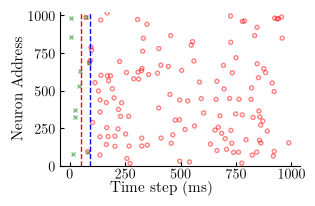

In [10]:
# Drawn at its printed size: half of \textwidth (A4, 1 in margins), golden ratio, as
# tex/tikz_snntorch.pdf, so both panels of fig:model share the same height at scale 1.
# The axes are then pinned on the rows of that diagram (fractions of its height): top
# of the axes on the output arrow tips, x axis on the bottom of the X[t] boxes, x label
# on the baseline of the "t = 0" labels. bbox=None keeps that exact geometry.
textwidth = 15.92  # (cm)
tikz_border = 2 / 72.27 * 2.54  # standalone border (cm)
tikz_y0, tikz_y1 = -3.427 - tikz_border, 3.627 + tikz_border  # bounding box (cm)
tikz_frac = lambda y: (y - tikz_y0) / (tikz_y1 - tikz_y0)
# the diagram is printed at tikz_scale of its natural width (11.5 cm plus the borders), and its
# fonts are enlarged by 1 / tikz_scale so that they print at the text size, as this raster
tikz_scale = 0.49 * textwidth / (11.5 + 2 * tikz_border)
# "t = 0" is a \papernormalsize node at y = -3.15 cm, centred on digits about 0.645 em high
t_baseline = -3.15 - 0.645 * normalsize / tikz_scale / 72.27 * 2.54 / 2  # (cm)

fig, ax = plt.subplots()
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=8, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=8, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)", va='baseline')
ax.xaxis.set_label_coords(0.5, tikz_frac(t_baseline), transform=fig.transFigure)
ax.tick_params(axis='x', pad=1.0)
ax.set_ylabel("Neuron Address", labelpad=1.5)
ax.set_ylim(-1., opt.N_neuron_show + 1.)
fig.subplots_adjust(top=tikz_frac(2.45 + 0.45 + 0.6), bottom=tikz_frac(-1.9 - 0.45), left=0.17, right=0.95)
printfig(fig, 'pattern', fig_width=0.49*textwidth, fig_height=0.49*textwidth/opt.phi, figpath=figpath, bbox=None, layout=None)
spikes.shape, spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].sum().item(), target[opt.i_pattern, :, :].sum().item()

### Raster legend (adds the evoked response)

Blue `+` = spikes re-emitted by the network in the evoked window. Blue aligning with red `o`
is a correct retrieval; blue without red = false positives (precision loss), red without
blue = misses (recall loss).

Saving as ../figures/target_init.pdf
Saving as ../figures/target_init.png
Saving as ../figures/target_init.svg


(torch.Size([16, 1024, 1100]), 50.0, 140.0)

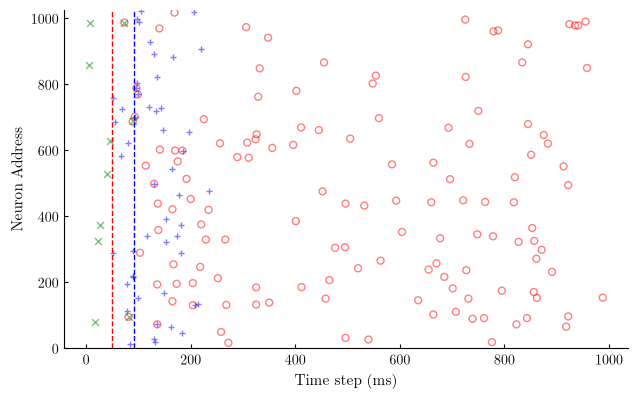

In [11]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
printfig(fig, 'target_init', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)
spikes.shape, spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].sum().item(), target[opt.i_pattern, :, :].sum().item()

## Supervised learning of the readout

`learn_model` refines `net.lin.weight` (the only trainable tensor) with:

- **loss** `SpikeF1scoreLoss = 1 - F1`, computed *only* on the evoked window
   (`[N_pretime+num_delay : N_time+N_pretime]` vs `target[:, num_delay:]`);
- **optimiser** adadelta (`rho = 1 - delta1 = 0.997`) and a **cosine LR** schedule with a
   16-epoch warmup, decaying `base_lr=40 mLR` to `final_lr=0.4 mLR`;
- **dropout 0.6** on the post-synaptic current, and a **fresh stochastic realisation** of
   the frozen pattern at every epoch (`pattern_object(seed=...)`) - data augmentation against
   memorising one exact realisation;
- per-epoch metrics on a second held-out realisation used as the trigger, scored against
   the frozen pattern and logged every `num_epochs // 64` epochs; all realisations are
   seeded from `seed`, so a run is reproducible.

Same `.pth` + `.lock` caching as the init stage.

In [12]:
model_filename = data_cache / f"{hd.opt.datetag}_vanilla.pth"
lock_filename = model_filename.with_suffix('.lock')
if RECOMPUTE:
    model_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    model_state_dict = torch.load(model_filename, map_location=torch.device(hd.opt.device))
    hd.net.load_state_dict(model_state_dict)
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Model weights loaded from {model_filename}") # Add a log message
except FileNotFoundError:
    if not lock_filename.exists():
        print(f"Model file not found: {model_filename}, training a new model.")
        lock_filename.touch(exist_ok=True)
         ##################
        hd.learn_model()
         ##################
        torch.save(hd.net.state_dict(), model_filename)
        lock_filename.unlink(missing_ok=True)
    else:
        print(f"Model file is locked: {lock_filename}, passing.")
hd.net.eval()

Model file not found: ../cached_data/2026-09-07_vanilla.pth, training a new model.
Train Epoch [000004/000256]	| Loss = 1.528e-01	| precision = 0.890	| recall = 0.809	| f1_score = 0.847	| 
Train Epoch [000008/000256]	| Loss = 1.365e-01	| precision = 0.913	| recall = 0.820	| f1_score = 0.864	| 
Train Epoch [000012/000256]	| Loss = 1.424e-01	| precision = 0.897	| recall = 0.822	| f1_score = 0.858	| 
Train Epoch [000016/000256]	| Loss = 1.796e-01	| precision = 0.851	| recall = 0.794	| f1_score = 0.820	| 
Train Epoch [000020/000256]	| Loss = 1.373e-01	| precision = 0.922	| recall = 0.812	| f1_score = 0.863	| 
Train Epoch [000024/000256]	| Loss = 1.657e-01	| precision = 0.880	| recall = 0.795	| f1_score = 0.834	| 
Train Epoch [000028/000256]	| Loss = 1.187e-01	| precision = 0.946	| recall = 0.825	| f1_score = 0.881	| 
Train Epoch [000032/000256]	| Loss = 1.280e-01	| precision = 0.926	| recall = 0.825	| f1_score = 0.872	| 
Train Epoch [000036/000256]	| Loss = 1.476e-01	| precision = 0.903	| 

Sequential(
  (lin): Linear(in_features=41984, out_features=1024, bias=False)
  (dropout): Dropout(p=0.6, inplace=False)
  (lif): Leaky()
)

### Post-learning evaluation

Same trigger protocol (same seeded realisation), evoked-window slices and frozen reference
as the baseline: compare with the analytic-init score (~0.85 f1) to quantify what supervised
refinement adds. `eval()` turns dropout off, so the pass is deterministic.

In [13]:
with torch.no_grad():
    target_full = torch.nn.functional.pad(target, (opt.N_pretime, opt.N_pretime))
    input_spikes = hd.get_input_spikes(target=cue, seed=hd.opt.seed)
    _, _, spikes = hd.forward_pass(input_spikes)
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = target[:, :, hd.opt.num_delay:]

    precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
    print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')
    # Per-motif scores (axis 0 = motif): the global score pools all spikes and can hide a motif that fails.
    for i_pattern in range(target_evoked.shape[0]):
        precision_i, recall_i, f1_score_i = get_scores(spikes_evoked[i_pattern], target_evoked[i_pattern])
        print(f'motif {i_pattern:2d}: precision = {precision_i:.3f}\t recall = {recall_i:.3f}\t f1_score = {f1_score_i:.3f} ')

precision = 0.877	 recall = 0.825	 f1_score = 0.850 
motif  0: precision = 1.000	 recall = 1.000	 f1_score = 1.000 
motif  1: precision = 1.000	 recall = 1.000	 f1_score = 1.000 
motif  2: precision = 1.000	 recall = 1.000	 f1_score = 1.000 
motif  3: precision = 1.000	 recall = 0.175	 f1_score = 0.298 
motif  4: precision = 1.000	 recall = 1.000	 f1_score = 1.000 
motif  5: precision = 1.000	 recall = 1.000	 f1_score = 1.000 
motif  6: precision = 1.000	 recall = 1.000	 f1_score = 1.000 
motif  7: precision = 1.000	 recall = 1.000	 f1_score = 1.000 
motif  8: precision = 1.000	 recall = 1.000	 f1_score = 1.000 
motif  9: precision = 1.000	 recall = 0.221	 f1_score = 0.362 
motif 10: precision = 0.410	 recall = 1.000	 f1_score = 0.582 
motif 11: precision = 1.000	 recall = 0.294	 f1_score = 0.454 
motif 12: precision = 1.000	 recall = 0.564	 f1_score = 0.722 
motif 13: precision = 1.000	 recall = 1.000	 f1_score = 1.000 
motif 14: precision = 1.000	 recall = 1.000	 f1_score = 1.000 
mo

Saving as ../figures/target.pdf
Saving as ../figures/target.png
Saving as ../figures/target.svg


(torch.Size([16, 1024, 1100]), 144.0, 140.0)

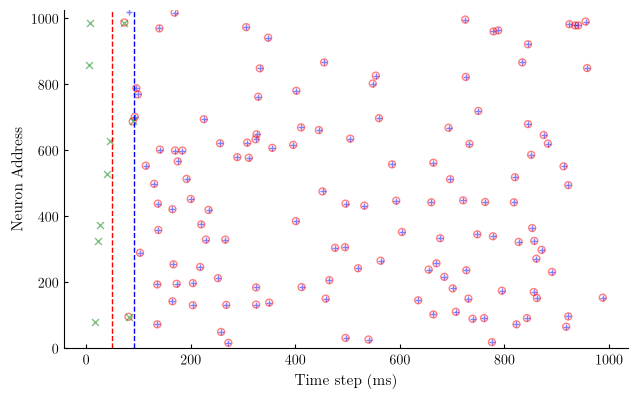

In [14]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
printfig(fig, 'target', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

### Weight histograms: sparsity signature

100-bin density histograms of the trained `net.lin.weight` (`41984 x 1024` = one delay tap
x one post-synaptic neuron), on log (and log-log) scales. A tall peak near zero with heavy
tails = a sparse code: few strong, selective synapses carry each memory.

Saving as ../figures/histogram_log.pdf
Saving as ../figures/histogram_log.png
Saving as ../figures/histogram_log.svg


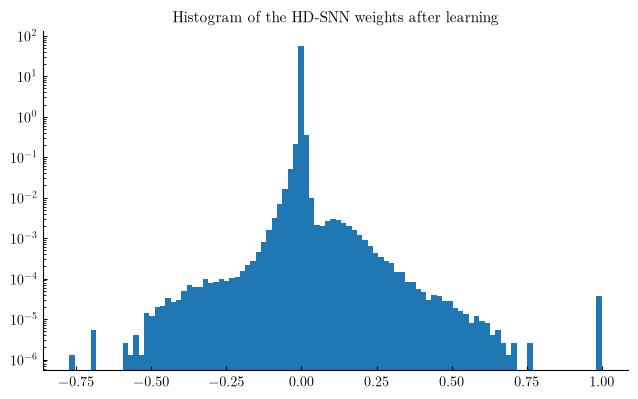

In [15]:
# hd.net.lin.bias.cpu().detach().numpy()
fig, ax = plt.subplots()
ax.hist(hd.net.lin.weight.cpu().detach().numpy().ravel(), bins=100, density=True) # pyright: ignore[reportCallIssue, reportAttributeAccessIssue]
ax.set_title(f"Histogram of the HD-SNN weights after learning")
ax.set_yscale('log')
printfig(fig, 'histogram_log', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)

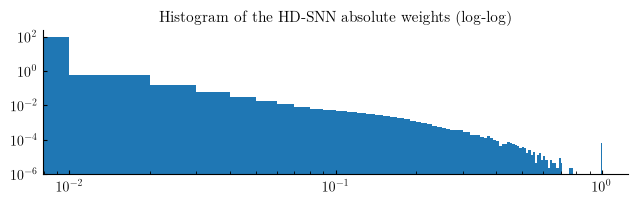

In [16]:
# hd.net.lin.bias.cpu().detach().numpy()
fig, ax = plt.subplots()
ax.hist(np.abs(hd.net.lin.weight.cpu().detach().numpy().ravel()), bins=100, density=True) # pyright: ignore[reportCallIssue, reportAttributeAccessIssue]
ax.set_title(f"Histogram of the HD-SNN absolute weights (log-log)")
ax.set_yscale('log')
ax.set_xscale('log')
printfig(fig, 'histogram_loglog', fig_width=opt.fig_width, fig_height=opt.fig_height/2, figpath=None)